# **Predicción** del valor comercial de una vivienda con un *árbol de regresión.*

In [4]:
import sklearn
import numpy as np
import pandas as pd

Se carga el archivo y se separa en entrenamiento y prueba

In [ ]:
# Descarga de datos
# ==============================================================================
datos = pd.read_csv('data/SaratogaHouses.csv', sep=",")

# Se renombran las columnas para que sean más descriptivas
datos.columns = ["precio","tamaño_lote", "antiguedad", "precio_terreno",
                 "area_construida", "universitarios", "dormitorios",
                 "chimenea", "baños", "habitaciones", "calefaccion",
                 "consumo_calefacion", "desague", "vistas_lago",
                 "nueva_construccion", "aire_acondicionado"]

In [6]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   precio              1728 non-null   int64  
 1   tamaño_lote         1728 non-null   float64
 2   antiguedad          1728 non-null   int64  
 3   precio_terreno      1728 non-null   int64  
 4   area_construida     1728 non-null   int64  
 5   universitarios      1728 non-null   int64  
 6   dormitorios         1728 non-null   int64  
 7   chimenea            1728 non-null   int64  
 8   baños               1728 non-null   float64
 9   habitaciones        1728 non-null   int64  
 10  calefaccion         1728 non-null   object 
 11  consumo_calefacion  1728 non-null   object 
 12  desague             1728 non-null   object 
 13  vistas_lago         1728 non-null   object 
 14  nueva_construccion  1728 non-null   object 
 15  aire_acondicionado  1728 non-null   object 
dtypes: flo

In [7]:
datos.head()

,precio,tamaño_lote,antiguedad,precio_terreno,area_construida,universitarios,dormitorios,chimenea,baños,habitaciones,calefaccion,consumo_calefacion,desague,vistas_lago,nueva_construccion,aire_acondicionado
0,132500,0.09,42,50000,906,35,2,1,1.0,5,electric,electric,septic,No,No,No
1,181115,0.92,0,22300,1953,51,3,0,2.5,6,hot water/steam,gas,septic,No,No,No
2,109000,0.19,133,7300,1944,51,4,1,1.0,8,hot water/steam,gas,public/commercial,No,No,No
3,155000,0.41,13,18700,1944,51,3,1,1.5,5,hot air,gas,septic,No,No,No
4,86060,0.11,0,15000,840,51,2,0,1.0,3,hot air,gas,public/commercial,No,Yes,Yes


In [8]:
datos.select_dtypes(include=['object']).describe()

,calefaccion,consumo_calefacion,desague,vistas_lago,nueva_construccion,aire_acondicionado
count,1728,1728,1728,1728,1728,1728
unique,3,3,3,2,2,2
top,hot air,gas,public/commercial,No,No,No
freq,1121,1197,1213,1713,1647,1093


In [9]:
datos.calefaccion.unique()

array(['electric', 'hot water/steam', 'hot air'], dtype=object)

In [ ]:
from sklearn.model_selection import train_test_split
N=len(datos)
cTrain=int(N*0.8) # 80% para entrenar y 20% para probar
cTest=N-cTrain
print(N,cTrain,cTest)
train_data,test_data= sklearn.model_selection.train_test_split(datos, train_size=cTrain, test_size=cTest)

1728 1382 346


In [11]:
train_data.head()

,precio,tamaño_lote,antiguedad,precio_terreno,area_construida,universitarios,dormitorios,chimenea,baños,habitaciones,calefaccion,consumo_calefacion,desague,vistas_lago,nueva_construccion,aire_acondicionado
263,101000,0.17,18,15800,912,52,2,0,2.0,3,electric,electric,public/commercial,No,No,No
388,248000,0.46,16,60500,2208,64,3,1,2.5,7,hot air,gas,public/commercial,No,No,Yes
1234,421000,0.31,5,80600,1911,62,3,1,2.5,6,hot air,gas,public/commercial,No,No,Yes
1466,219000,0.47,27,24600,1719,64,3,1,1.5,5,electric,electric,public/commercial,No,No,No
479,290000,0.15,13,400,1758,47,2,1,2.5,6,hot air,gas,public/commercial,No,No,Yes


## Pipeline para los atributos categóricos

In [12]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 6 atributos categóricos
cat_attribs = ['calefaccion','consumo_calefacion','desague','vistas_lago','nueva_construccion','aire_acondicionado']

cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("cat_encoder", OneHotEncoder(sparse_output=False))
    ])

## Pipeline para los atributos numéricos

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

# 9 atributos numéricos
num_attribs = ['antiguedad','precio_terreno','area_construida','universitarios','dormitorios','chimenea','habitaciones','tamaño_lote','baños']

num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())

    ])

## Pipeline completo

In [14]:
from sklearn.compose import ColumnTransformer

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs),
])

### Extraemos las etiquetas de clase

In [15]:
y_train = train_data["precio"]
y_train

263     101000
388     248000
1234    421000
1466    219000
479     290000
         ...  
430     138000
523     303000
168     115000
260     335000
950     285000
Name: precio, Length: 1382, dtype: int64

In [16]:
X_train = full_pipeline.fit_transform(train_data)

In [17]:
X_train.shape

(1382, 24)

Quedan 24 valores por el OneHotEncoding (9 de los atributos numéricos + 15 (3+3+3+2+2+2) de los categóricos)

In [18]:
X_train[0,:]

array([-0.34113399, -0.53077279, -1.35439328, -0.33794549, -1.42100277,
       -1.0843308 , -1.75762249, -0.46547374,  0.16113053,  1.        ,
        0.        ,  0.        ,  1.        ,  0.        ,  0.        ,
        0.        ,  1.        ,  0.        ,  1.        ,  0.        ,
        1.        ,  0.        ,  1.        ,  0.        ])

In [19]:
X_train[1,:]

array([-0.40925727,  0.73580321,  0.74031246,  0.81690472, -0.20047708,
        0.72550636, -0.02166803, -0.06139168,  0.92374147,  0.        ,
        1.        ,  0.        ,  0.        ,  1.        ,  0.        ,
        0.        ,  1.        ,  0.        ,  1.        ,  0.        ,
        1.        ,  0.        ,  0.        ,  1.        ])

# Árboles de decisión
## Algoritmo DecisionTreeRegressor

-45554.77342253963


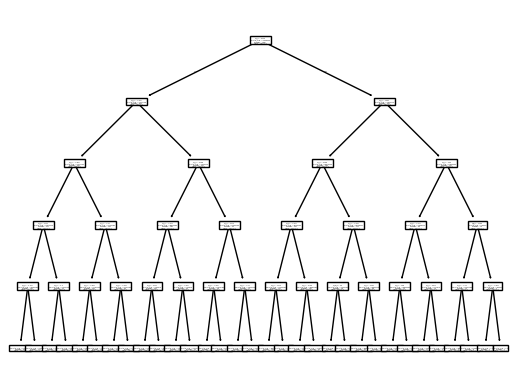

In [20]:
from sklearn import tree
from sklearn.model_selection import cross_val_score
# criterion: “squared_error”, “friedman_mse”, “absolute_error”, “poisson”
modelo1 = tree.DecisionTreeRegressor(criterion='absolute_error',max_depth=5,splitter="best",random_state=123)
modelo1.fit(X_train, y_train)
puntajes1 = cross_val_score(modelo1, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
print(puntajes1.mean())

tree.plot_tree(modelo1)
tree.export_graphviz(decision_tree=modelo1, class_names=True,out_file="Arbol Viviendas1.dot")

# Modificando los hiperparámetros

-54299.86721079893


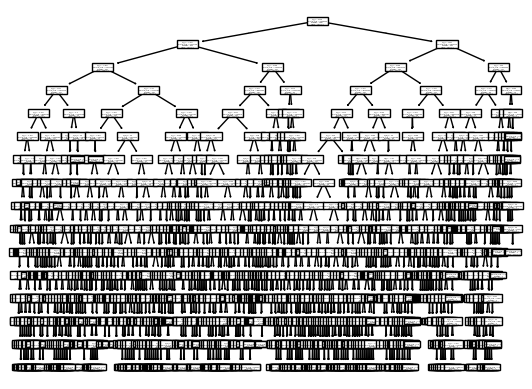

In [21]:
from sklearn import tree
from sklearn.model_selection import cross_val_score
# criterion: “squared_error”, “friedman_mse”, “absolute_error”, “poisson”
modelo2 = tree.DecisionTreeRegressor(criterion='absolute_error',max_depth=15,splitter="best",random_state=123)
modelo2.fit(X_train, y_train)
puntajes2 = cross_val_score(modelo2, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
print(puntajes2.mean())

tree.plot_tree(modelo2)
tree.export_graphviz(decision_tree=modelo2, class_names=True,out_file="Arbol Viviendas2.dot")

# Analicemos el desempeño en el conjunto de prueba

In [22]:
X_test = full_pipeline.transform(test_data)
X_test

array([[-0.30707235, -0.21342042, -0.15187702, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.0676057 ,  0.84630984, -0.77253057, ...,  0.        ,
         1.        ,  0.        ],
       [-0.40925727,  0.3872823 ,  0.28452001, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [-0.17082578,  1.0673231 ,  0.70152162, ...,  0.        ,
         0.        ,  1.        ],
       [-0.57956547, -0.90479524, -0.25855185, ...,  0.        ,
         0.        ,  1.        ],
       [-0.30707235, -0.51377177, -0.43795952, ...,  0.        ,
         0.        ,  1.        ]], shape=(346, 24))

In [23]:
y_pred1 = modelo1.predict(X_test)
y_pred1

array([188000. , 160500. , 359770. , 160500. , 223000. ,  87734. ,
       123000. , 160500. , 284747.5, 141160. , 271000. , 155750. ,
       374000. , 188000. , 223000. , 121000. , 335000. , 150000. ,
       284747.5, 335000. , 121000. , 160500. , 150000. , 155750. ,
       121000. , 284747.5, 284747.5, 121000. , 211250. , 335000. ,
       240500. , 150000. , 240500. , 188000. , 240500. , 150000. ,
       150000. , 150000. , 335000. , 188000. , 160500. , 188000. ,
       257000. , 374000. , 150000. , 271000. , 123000. , 211250. ,
       284747.5, 150000. , 211250. , 121000. , 257000. , 150000. ,
       150000. , 150000. , 284747.5, 257000. , 123000. , 205000. ,
       150000. , 224000. , 150000. , 374000. , 224000. , 211250. ,
       240500. , 180000. , 150000. , 205000. , 205000. , 188000. ,
       121000. , 121000. , 180000. , 284747.5, 121000. , 240500. ,
       240500. , 211250. , 335000. , 257000. , 374000. , 257000. ,
       160500. , 257000. , 160500. , 188000. , 271000. , 15000

In [24]:
y_pred2 = modelo2.predict(X_test)
y_pred2

array([216900. ,  71500. , 335000. , 146000. , 220000. ,  72000. ,
       120000. , 500000. , 248220. , 160000. , 249900. , 113000. ,
       760000. , 172850. , 198500. , 125000. , 342000. , 206000. ,
       212500. , 340000. , 173000. , 180000. , 123500. , 115800. ,
       100500. , 292500. , 250000. , 132000. , 212000. , 307890. ,
       181280. , 155500. , 260000. , 197568. , 225000. , 155500. ,
       135000. , 123000. , 292000. , 245000. , 100000. , 177500. ,
       215000. , 349900. , 115000. , 175000. , 145000. , 235000. ,
       239900. , 155500. , 225000. ,  84000. , 289900. , 155500. ,
       131600. , 334000. , 220000. , 315371. , 127000. , 132500. ,
       120000. , 201000. , 155500. , 328463. , 153000. , 225000. ,
       225000. , 171000. , 155500. , 142900. , 163500. , 172850. ,
       115000. , 100500. , 130000. , 290000. , 139000. , 276510. ,
       207450. , 212000. , 246500. , 290000. , 411000. , 265000. ,
       170000. , 320900. , 217300. , 172850. , 253000. , 16650

In [25]:
y_test = test_data["precio"]

In [26]:
y_test

1396    230000
532     120000
702     285000
1165    208000
664     240000
         ...  
1232    230000
655     267000
1711    350000
1292    255500
993     125500
Name: precio, Length: 346, dtype: int64

In [27]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(
        y_true  = y_test,
        y_pred  = y_pred1
       )
print(f"El error medio absoluto del modelo 1 es: {mae}")

El error medio absoluto del modelo 1 es: 42710.59248554913


In [28]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(
        y_true  = y_test,
        y_pred  = y_pred2
       )
print(f"El error medio absoluto del modelo 1 es: {mae}")

El error medio absoluto del modelo 1 es: 51902.02167630058


# Ajuste de hiperparámetros con GridSearch

In [29]:
from sklearn.model_selection import GridSearchCV

parameters={"criterion":["absolute_error","squared_error", "friedman_mse"],
            "splitter":["best","random"],
            "max_depth" : [1,3,5,7,9,11,12],
            "max_leaf_nodes":[None,10,20,30,40,50,60,70,80,90] }

grid = GridSearchCV(
        estimator = tree.DecisionTreeRegressor(),
        param_grid=parameters,
        cv=5,
        scoring='neg_mean_absolute_error'
        )

grid.fit(X_train, y_train)

,estimator,DecisionTreeRegressor()
,param_grid,"{'criterion': ['absolute_error', 'squared_error', ...], 'max_depth': [1, 3, ...], 'max_leaf_nodes': [None, 10, ...], 'splitter': ['best', 'random']}"
,scoring,'neg_mean_absolute_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'absolute_error'


In [30]:
# Mejores hiperparámetros
grid.best_params_

{'criterion': 'absolute_error',
 'max_depth': 7,
 'max_leaf_nodes': 20,
 'splitter': 'best'}

In [31]:
modelo3 = tree.DecisionTreeRegressor(criterion='absolute_error',max_depth=12,splitter="best",max_leaf_nodes=20)
modelo3.fit(X_train, y_train)


,criterion,'absolute_error'
,splitter,'best'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,20
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [32]:
y_pred3 = modelo3.predict(X_test)
y_pred3

array([188000. , 160500. , 359770. , 160500. , 224000. , 124000. ,
       123000. , 160500. , 284747.5, 124000. , 216500. , 169900. ,
       367500. , 188000. , 224000. , 124000. , 367500. , 150000. ,
       284747.5, 367500. , 124000. , 160500. , 150000. , 169900. ,
       124000. , 284747.5, 284747.5, 124000. , 216500. , 367500. ,
       240500. , 150000. , 240500. , 188000. , 240500. , 150000. ,
       150000. , 150000. , 367500. , 188000. , 160500. , 188000. ,
       257000. , 367500. , 150000. , 216500. , 123000. , 216500. ,
       284747.5, 150000. , 216500. , 124000. , 257000. , 150000. ,
       150000. , 150000. , 284747.5, 257000. , 123000. , 205000. ,
       150000. , 272500. , 150000. , 367500. , 272500. , 216500. ,
       240500. , 169900. , 150000. , 205000. , 205000. , 188000. ,
       124000. , 124000. , 169900. , 284747.5, 124000. , 240500. ,
       240500. , 216500. , 367500. , 257000. , 367500. , 257000. ,
       160500. , 257000. , 160500. , 188000. , 216500. , 15000

In [33]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(
        y_true  = y_test,
        y_pred  = y_pred3
       )
print(f"El error medio absoluto del modelo 3 es: {mae}")

El error medio absoluto del modelo 3 es: 44933.260115606936
